# Phase 2 — Machine Learning
## Lesson 2.1.5: Overfitting, Underfitting, and Generalization

**Series:** AI & ML — Learn • Build • Grow  
**Module:** 2.1 — ML Fundamentals  
**Framework:** PyTorch  
**Environment:** Jupyter Notebook · CPU compatible

In this lesson, we will see why a model can perform poorly even after training, and why a low training loss does not automatically mean that a model has learned a useful pattern.

We will compare three models on a small, noisy regression problem:

- a **linear model** that is too simple for the curved pattern;
- a **compact neural network** that learns the useful relationship;
- a **high-capacity neural network** that can start memorizing noise when trained for too long.

> This is a deliberately controlled synthetic example. The data-generating function is shown only to help us visualize the task. The models never receive that function as an input.

### Learning objectives

By the end, you should be able to:

1. Explain underfitting, overfitting, and generalization in plain language.
2. Recognize common training/validation loss patterns.
3. Compare models with different capacity.
4. Explain why validation data helps diagnose overfitting.
5. Keep the test set separate until the final evaluation.

**Connection to previous lessons:** We reuse the train/validation/test roles from Lesson 2.1.4. The focus now shifts from creating the split to understanding what the model's performance on each split tells us.

## 1. The central idea: learning a pattern, not memorizing examples

A useful model should capture a relationship that continues to work for new examples. It should not simply reproduce the training observations.

- **Underfitting:** the model is too limited to capture the important pattern. Training and validation errors are both relatively high.
- **Good fit:** the model captures the main pattern and performs similarly on training and unseen validation examples.
- **Overfitting:** the model fits details specific to the training set, including random noise. Training error keeps falling while validation error stops improving or gets worse.
- **Generalization:** the model performs well on new examples drawn from the same kind of problem.

We will create a simple experiment that makes these ideas visible.

## 2. Import libraries and make the experiment reproducible

We use PyTorch for the models, loss functions, optimizers, and training loop. NumPy and pandas help with data inspection; Matplotlib creates the charts.

The experiment is designed to run on CPU. No NVIDIA GPU is required.

In [27]:
from pathlib import Path
import copy
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

# Work whether Jupyter starts in lesson_example/ or lesson_example/notebooks/.
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "outputs").is_dir():
    OUTPUT_DIR = CURRENT_DIR / "outputs"
elif (CURRENT_DIR.parent / "outputs").is_dir():
    OUTPUT_DIR = CURRENT_DIR.parent / "outputs"
else:
    OUTPUT_DIR = CURRENT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(1)

DEVICE = torch.device("cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch version: 2.15.0+cpu
Device: cpu


## 3. Create a small, noisy regression dataset

Imagine a sensor produces one numeric input, `x`, and we want to predict a related output, `y`.

The hidden signal is:

\[
f(x) = \sin(1.4x) + 0.18x
\]

We add random noise to create the observed target:

\[
y = f(x) + \epsilon
\]

The random term \(\epsilon\) represents measurement noise or other effects not explained by our simple input.

The `true_signal` column is available only because we generated this synthetic data. In a real-world problem, we usually do not know the exact function that created the observations.

In [28]:
N_EXAMPLES = 240
NOISE_STD = 0.45

x_ordered = torch.linspace(-3.0, 3.0, N_EXAMPLES).unsqueeze(1)
shuffle_order = torch.randperm(N_EXAMPLES)
X_all = x_ordered[shuffle_order]


def underlying_signal(x: torch.Tensor) -> torch.Tensor:
    """The smooth signal used only to generate and visualize synthetic data."""
    return torch.sin(1.4 * x) + 0.18 * x


noise = NOISE_STD * torch.randn(N_EXAMPLES, 1)
y_all = underlying_signal(X_all) + noise
true_signal_all = underlying_signal(X_all)

print("Feature tensor:", tuple(X_all.shape))
print("Target tensor:", tuple(y_all.shape))

Feature tensor: (240, 1)
Target tensor: (240, 1)


## 4. Inspect the observations

Each row contains one feature and one observed target. Notice that the points do not fall perfectly on a smooth curve. That is intentional: real measurements often contain noise.

In [29]:
dataset_df = pd.DataFrame({
    "x": X_all.squeeze(1).numpy(),
    "observed_target": y_all.squeeze(1).numpy(),
    "true_signal_for_visualization_only": true_signal_all.squeeze(1).numpy(),
})
dataset_df.head(10)

,x,observed_target,true_signal_for_visualization_only
0,-0.439331,-0.714278,-0.656089
1,-2.924686,-0.129414,0.288695
2,0.313807,0.606105,0.481819
3,-0.112971,-0.420329,-0.177835
4,2.472803,0.338385,0.130223
5,1.016736,0.779824,1.172174
6,1.619247,1.046578,1.058782
7,0.615063,0.710303,0.869263
8,-1.041841,-1.280852,-1.181241
9,-1.895397,-0.245119,-0.810064


## 5. Visualize the hidden signal and noisy observations

The grey curve is the smooth signal used to generate the data. The dots are the observations the model receives.

The model sees only `x` and `observed_target`; it does not see the grey curve or the noise values separately.

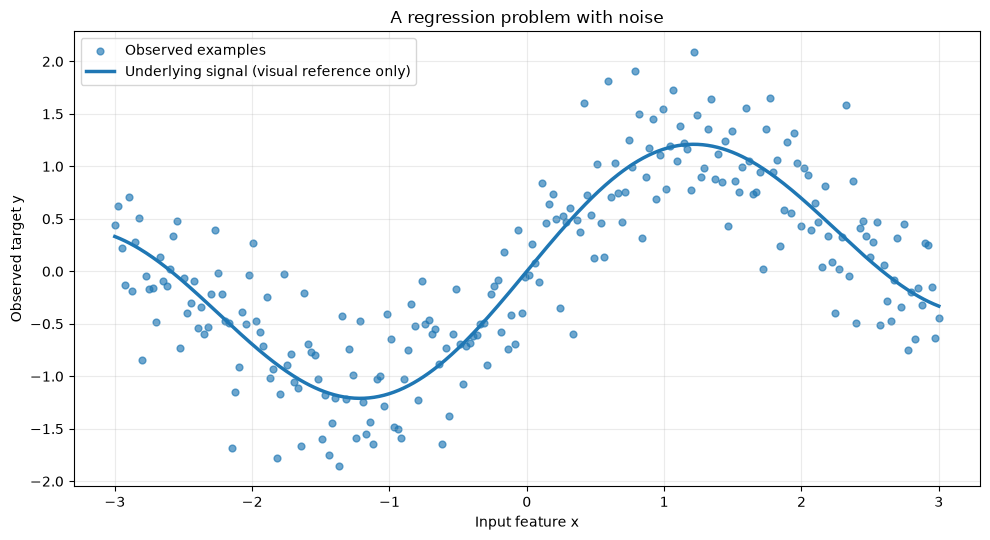

In [30]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(X_all.numpy(), y_all.numpy(), s=24, alpha=0.65, label="Observed examples")
plot_x = torch.linspace(-3.0, 3.0, 500).unsqueeze(1)
ax.plot(plot_x.numpy(), underlying_signal(plot_x).numpy(), linewidth=2.5,
        label="Underlying signal (visual reference only)")
ax.set_title("A regression problem with noise")
ax.set_xlabel("Input feature x")
ax.set_ylabel("Observed target y")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "noisy_dataset.png", dpi=160)
plt.show()

## 6. Create training, validation, and test sets

We use the same split idea from Lesson 2.1.4:

- **Training set:** used to update model parameters.
- **Validation set:** used during development to compare models and monitor overfitting.
- **Test set:** kept aside until we have selected the model.

The split is 70% / 15% / 15%. The split is reproducible because we use a fixed random seed.

In [31]:
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

split_generator = torch.Generator().manual_seed(2026)
all_indices = torch.randperm(N_EXAMPLES, generator=split_generator)

n_train = int(TRAIN_RATIO * N_EXAMPLES)
n_validation = int(VALIDATION_RATIO * N_EXAMPLES)

train_indices = all_indices[:n_train]
validation_indices = all_indices[n_train:n_train + n_validation]
test_indices = all_indices[n_train + n_validation:]

X_train, y_train = X_all[train_indices], y_all[train_indices]
X_validation, y_validation = X_all[validation_indices], y_all[validation_indices]
X_test, y_test = X_all[test_indices], y_all[test_indices]

print(f"Training examples:   {len(train_indices)}")
print(f"Validation examples: {len(validation_indices)}")
print(f"Test examples:       {len(test_indices)}")

Training examples:   168
Validation examples: 36
Test examples:       36


## 7. Verify that the splits are separate

No observation should appear in more than one split, and every observation should appear in exactly one split.

In [32]:
train_set = set(train_indices.tolist())
validation_set = set(validation_indices.tolist())
test_set = set(test_indices.tolist())

assert train_set.isdisjoint(validation_set)
assert train_set.isdisjoint(test_set)
assert validation_set.isdisjoint(test_set)
assert len(train_set | validation_set | test_set) == N_EXAMPLES

print("Split verification passed: no overlap and full coverage.")

Split verification passed: no overlap and full coverage.


## 8. Plot the three data partitions

The three panels contain different observations from the same underlying problem. We will train only with the first panel, monitor the second, and reserve the third for the final check.

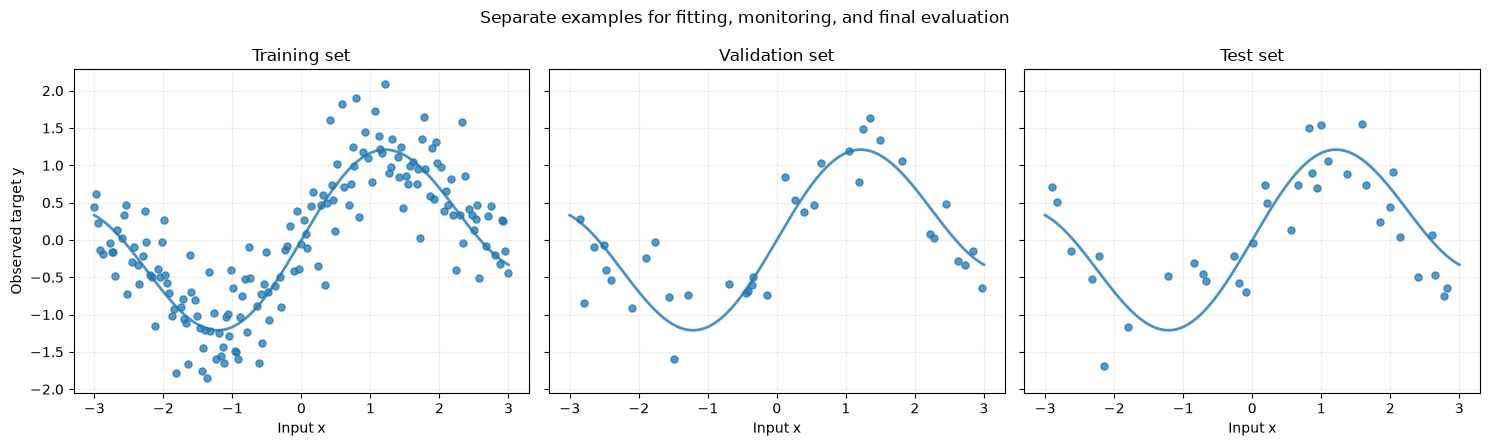

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
partitions = [
    (X_train, y_train, "Training set"),
    (X_validation, y_validation, "Validation set"),
    (X_test, y_test, "Test set"),
]
for ax, (x_part, y_part, title) in zip(axes, partitions):
    ax.scatter(x_part.numpy(), y_part.numpy(), s=26, alpha=0.75)
    ax.plot(plot_x.numpy(), underlying_signal(plot_x).numpy(), linewidth=2, alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel("Input x")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Observed target y")
fig.suptitle("Separate examples for fitting, monitoring, and final evaluation")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "three_data_partitions.png", dpi=160)
plt.show()

## 9. Define three models with different capacity

Model capacity is the range of patterns a model can represent.

We will compare:

1. **Linear baseline:** only two trainable parameters. It can represent a straight line, not this curved signal.
2. **Compact neural network:** one hidden layer with 32 units. It has enough flexibility for the broad pattern in this example.
3. **High-capacity neural network:** two hidden layers with 128 units each. It can represent much more complex curves, including details that may be noise.

A larger model is not automatically better. It needs enough useful data and an appropriate training process.

In [34]:
class LinearBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(1, 1)

    def forward(self, x):
        return self.layer(x)


class CompactMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)


class HighCapacityMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 128),
            nn.Tanh(),
            nn.Linear(128, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.network(x)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


for model_name, model in [
    ("Linear baseline", LinearBaseline()),
    ("Compact MLP", CompactMLP()),
    ("High-capacity MLP", HighCapacityMLP()),
]:
    print(f"{model_name:20s}: {count_parameters(model):,} trainable parameters")

Linear baseline     : 2 trainable parameters
Compact MLP         : 97 trainable parameters
High-capacity MLP   : 16,897 trainable parameters


## 10. Understand the loss we will monitor

For this regression task, we use Mean Squared Error (MSE):

\[
\mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2
\]

A smaller MSE means predictions are closer to the observed targets on average. However, **which dataset** the MSE is measured on matters. Training loss and validation loss answer different questions.

In [35]:
loss_function = nn.MSELoss()

# A tiny numeric example to make the loss calculation concrete.
example_targets = torch.tensor([[1.0], [2.0], [3.0]])
example_predictions = torch.tensor([[1.5], [1.5], [2.0]])
example_loss = loss_function(example_predictions, example_targets)
print(f"Example MSE: {example_loss.item():.4f}")

Example MSE: 0.5000


## 11. Create reusable training and evaluation functions

The training function updates parameters using **only** the training set. After every epoch, it measures loss on both training and validation data without updating parameters during evaluation.

We save the model state with the lowest validation loss. The history also retains the final epoch so we can see what happens when a high-capacity model continues training after validation performance has stopped improving.

In [36]:
def evaluate_mse(model, features, targets):
    model.eval()
    with torch.no_grad():
        predictions = model(features)
        loss = loss_function(predictions, targets)
    return float(loss.item())


def train_model(model, model_name, epochs, learning_rate):
    torch.manual_seed(100)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    best_validation_loss = float("inf")
    best_epoch = None
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        training_predictions = model(X_train)
        training_loss = loss_function(training_predictions, y_train)
        training_loss.backward()
        optimizer.step()

        # Evaluate after the update. These calls do not calculate gradients.
        training_mse = evaluate_mse(model, X_train, y_train)
        validation_mse = evaluate_mse(model, X_validation, y_validation)
        history.append({
            "model": model_name,
            "epoch": epoch,
            "training_mse": training_mse,
            "validation_mse": validation_mse,
        })

        if validation_mse < best_validation_loss:
            best_validation_loss = validation_mse
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    final_state = copy.deepcopy(model.state_dict())
    history_df = pd.DataFrame(history)
    best_row = history_df.loc[history_df["validation_mse"].idxmin()]

    return {
        "model": model,
        "model_name": model_name,
        "history": history_df,
        "best_epoch": int(best_epoch),
        "best_validation_loss": float(best_validation_loss),
        "best_training_loss": float(best_row["training_mse"]),
        "best_state": best_state,
        "final_state": final_state,
        "final_training_loss": float(history_df.iloc[-1]["training_mse"]),
        "final_validation_loss": float(history_df.iloc[-1]["validation_mse"]),
        "epochs": int(epochs),
        "learning_rate": float(learning_rate),
        "parameter_count": count_parameters(model),
    }

## 12. Train the linear baseline: an example of underfitting

The linear model is intentionally limited. We train it for 500 epochs, but more training cannot make a straight-line model represent a curved relationship.

In [37]:
underfit_result = train_model(
    model=LinearBaseline(),
    model_name="Linear baseline",
    epochs=500,
    learning_rate=0.01,
)

print("Best validation epoch:", underfit_result["best_epoch"])
print(f"Best validation MSE: {underfit_result['best_validation_loss']:.4f}")
print(f"Training MSE at that epoch: {underfit_result['best_training_loss']:.4f}")

Best validation epoch: 397
Best validation MSE: 0.5237
Training MSE at that epoch: 0.5625


## 13. Train the compact network: a useful fit

The compact network has more flexibility than a straight line. We will use the checkpoint with the lowest validation loss as its representative model.

In [38]:
balanced_result = train_model(
    model=CompactMLP(),
    model_name="Compact MLP",
    epochs=1500,
    learning_rate=0.01,
)

print("Best validation epoch:", balanced_result["best_epoch"])
print(f"Best validation MSE: {balanced_result['best_validation_loss']:.4f}")
print(f"Training MSE at that epoch: {balanced_result['best_training_loss']:.4f}")

Best validation epoch: 673
Best validation MSE: 0.1506
Training MSE at that epoch: 0.1714


## 14. Train the high-capacity network for a long time

This network has many more parameters. We deliberately train it for 6,000 epochs so we can observe a classic overfitting pattern.

We are not recommending 6,000 epochs for real projects. This is a controlled demonstration of what can happen when a flexible model keeps adapting to the training observations, including their noise.

In [39]:
overfit_result = train_model(
    model=HighCapacityMLP(),
    model_name="High-capacity MLP",
    epochs=6000,
    learning_rate=0.003,
)

print("Best validation epoch:", overfit_result["best_epoch"])
print(f"Best validation MSE: {overfit_result['best_validation_loss']:.4f}")
print(f"Final training MSE: {overfit_result['final_training_loss']:.4f}")
print(f"Final validation MSE: {overfit_result['final_validation_loss']:.4f}")

Best validation epoch: 89
Best validation MSE: 0.1497
Final training MSE: 0.0735
Final validation MSE: 0.3058


## 15. Compare training and validation curves

Look at the high-capacity model:

- training loss continues to decrease;
- validation loss reaches a minimum, then increases;
- the growing difference is a warning that the model is fitting training-specific details.

This is one of the most useful visual signs of overfitting.

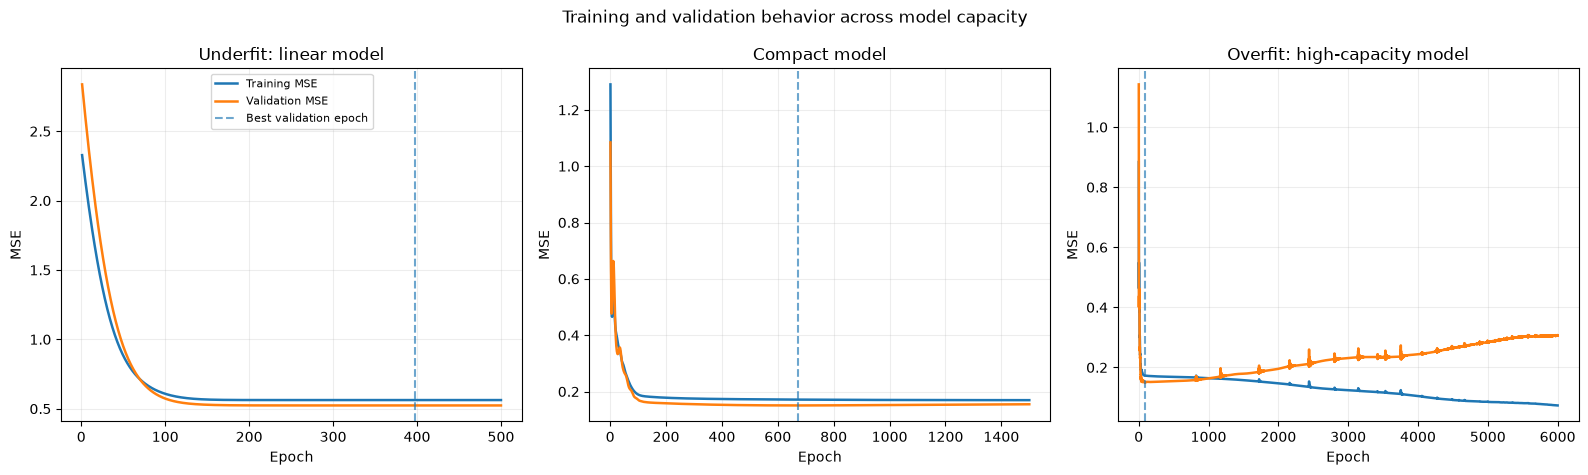

In [40]:
all_histories = pd.concat([
    underfit_result["history"],
    balanced_result["history"],
    overfit_result["history"],
], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, result, title in zip(
    axes,
    [underfit_result, balanced_result, overfit_result],
    ["Underfit: linear model", "Compact model", "Overfit: high-capacity model"],
):
    h = result["history"]
    ax.plot(h["epoch"], h["training_mse"], label="Training MSE", linewidth=1.8)
    ax.plot(h["epoch"], h["validation_mse"], label="Validation MSE", linewidth=1.8)
    ax.axvline(result["best_epoch"], linestyle="--", alpha=0.65, label="Best validation epoch")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.22)
axes[0].legend(fontsize=8)
fig.suptitle("Training and validation behavior across model capacity")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loss_curves_by_model.png", dpi=160)
plt.show()

## 16. Zoom in on the overfitting pattern

The raw validation curve may fluctuate because the validation set is finite. A rolling average makes the longer-term trend easier to see, while the raw line remains available in the background.

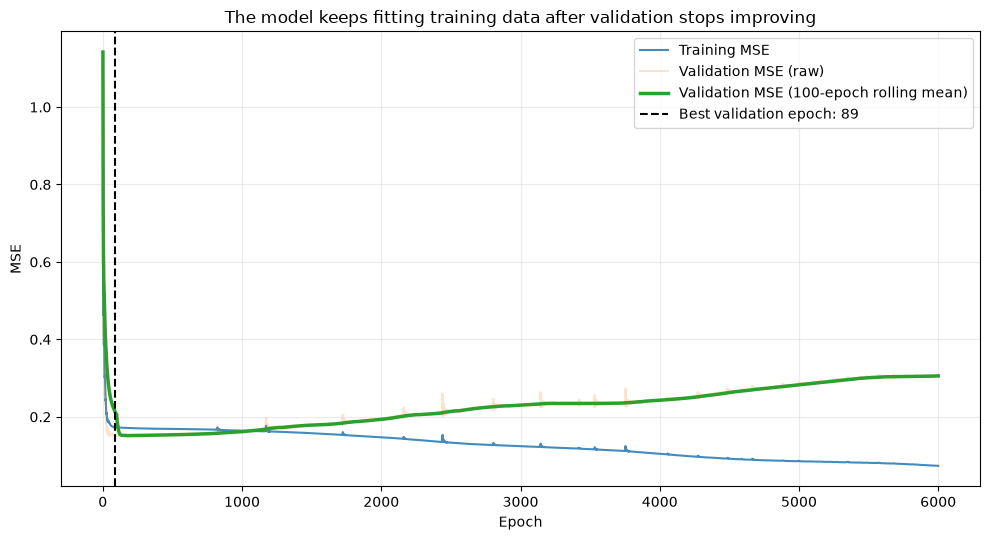

In [41]:
overfit_history = overfit_result["history"].copy()
overfit_history["validation_mse_smooth"] = overfit_history["validation_mse"].rolling(
    window=100, min_periods=1
).mean()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(overfit_history["epoch"], overfit_history["training_mse"],
        label="Training MSE", alpha=0.85)
ax.plot(overfit_history["epoch"], overfit_history["validation_mse"],
        label="Validation MSE (raw)", alpha=0.22)
ax.plot(overfit_history["epoch"], overfit_history["validation_mse_smooth"],
        label="Validation MSE (100-epoch rolling mean)", linewidth=2.5)
ax.axvline(overfit_result["best_epoch"], linestyle="--", color="black",
           label=f"Best validation epoch: {overfit_result['best_epoch']}")
ax.set_title("The model keeps fitting training data after validation stops improving")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "overfitting_loss_detail.png", dpi=160)
plt.show()

## 17. Restore the best validation checkpoint

The training function saved the parameters from the epoch with the lowest validation loss. We can restore those parameters instead of keeping the final epoch.

This introduces the idea of checkpoint selection / early stopping. We are not covering every practical early-stopping strategy here; the important lesson is that validation behavior can tell us when continued training is no longer helping.

In [42]:
overfit_best_model = HighCapacityMLP()
overfit_best_model.load_state_dict(overfit_result["best_state"])
overfit_final_model = HighCapacityMLP()
overfit_final_model.load_state_dict(overfit_result["final_state"])

print("Best checkpoint validation MSE:", evaluate_mse(
    overfit_best_model, X_validation, y_validation
))
print("Final checkpoint validation MSE:", evaluate_mse(
    overfit_final_model, X_validation, y_validation
))

Best checkpoint validation MSE: 0.14966922998428345
Final checkpoint validation MSE: 0.30577895045280457


## 18. Compare the model curves

The next chart shows predictions made by:

- the underfitting linear model at its best validation checkpoint;
- the compact model at its best validation checkpoint;
- the high-capacity model after its full 6,000 training epochs;
- the high-capacity model restored to its best validation checkpoint.

The compact model and the best high-capacity checkpoint learn the broad signal. The final high-capacity model bends more to follow individual noisy observations.

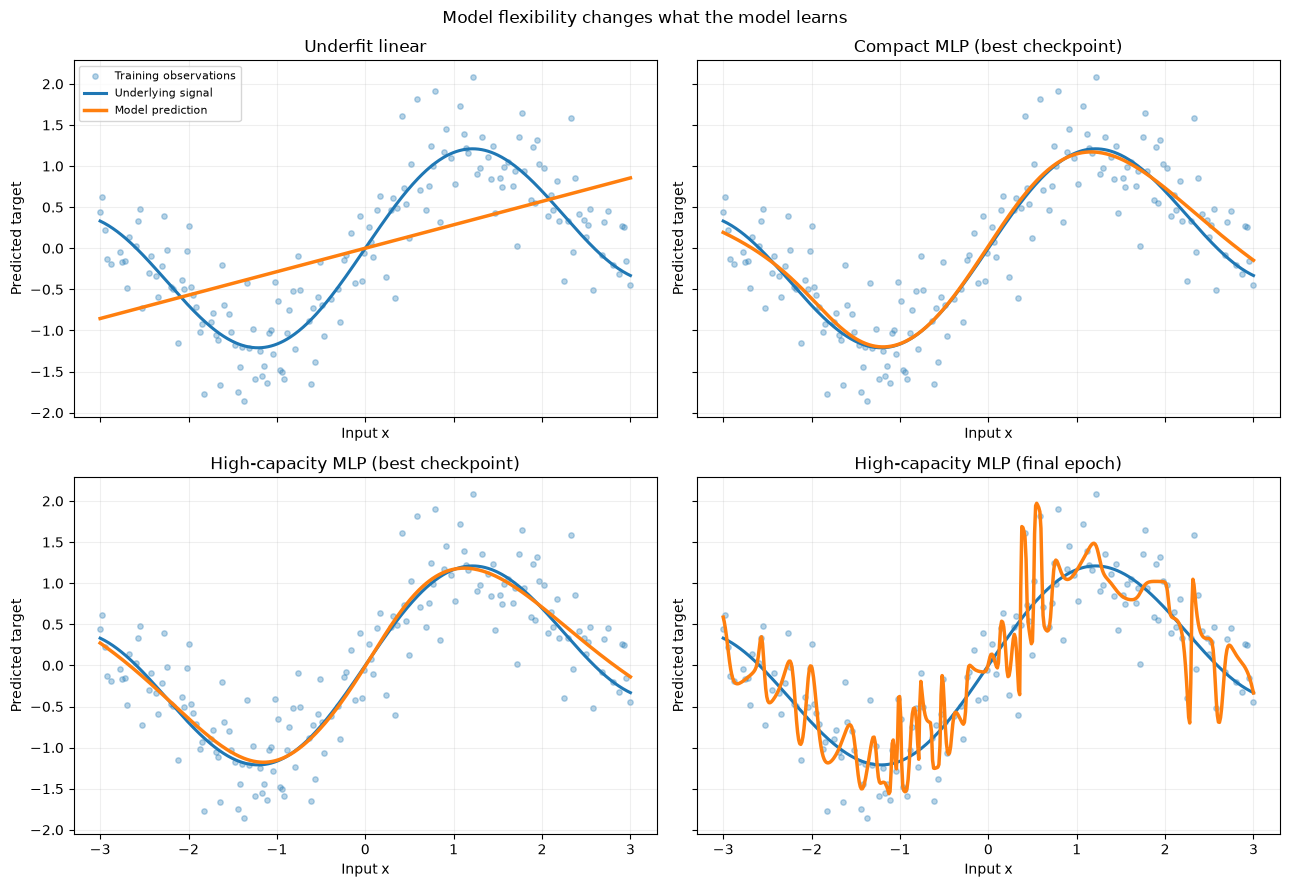

In [43]:
underfit_best_model = LinearBaseline()
underfit_best_model.load_state_dict(underfit_result["best_state"])
balanced_best_model = CompactMLP()
balanced_best_model.load_state_dict(balanced_result["best_state"])

prediction_grid = torch.linspace(-3.0, 3.0, 500).unsqueeze(1)
models_for_curve = {
    "Underfit linear": underfit_best_model,
    "Compact MLP (best checkpoint)": balanced_best_model,
    "High-capacity MLP (best checkpoint)": overfit_best_model,
    "High-capacity MLP (final epoch)": overfit_final_model,
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
for ax, (name, fitted_model) in zip(axes.flat, models_for_curve.items()):
    fitted_model.eval()
    with torch.no_grad():
        predicted_curve = fitted_model(prediction_grid).numpy()
    ax.scatter(X_train.numpy(), y_train.numpy(), s=15, alpha=0.32, label="Training observations")
    ax.plot(prediction_grid.numpy(), underlying_signal(prediction_grid).numpy(),
            linewidth=2.2, label="Underlying signal")
    ax.plot(prediction_grid.numpy(), predicted_curve, linewidth=2.5, label="Model prediction")
    ax.set_title(name)
    ax.set_xlabel("Input x")
    ax.set_ylabel("Predicted target")
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Model flexibility changes what the model learns")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "model_fit_comparison.png", dpi=160)
plt.show()

## 19. Compare the results at the selected checkpoints and at the final epoch

A good fit is not simply the model with the smallest training error. We compare parameter count, training loss, and validation loss.

The high-capacity model's **best validation checkpoint** may perform well, but after many more epochs its training error becomes much lower while validation error gets worse. That is the overfitting signal.

In [44]:
comparison_rows = []
for role, result in [
    ("Underfitting example", underfit_result),
    ("Compact model", balanced_result),
    ("High-capacity model", overfit_result),
]:
    comparison_rows.append({
        "model": result["model_name"],
        "teaching_role": role,
        "parameters": result["parameter_count"],
        "best_epoch": result["best_epoch"],
        "best_checkpoint_train_mse": result["best_training_loss"],
        "best_checkpoint_validation_mse": result["best_validation_loss"],
        "final_train_mse": result["final_training_loss"],
        "final_validation_mse": result["final_validation_loss"],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.round(4)

,model,teaching_role,parameters,best_epoch,best_checkpoint_train_mse,best_checkpoint_validation_mse,final_train_mse,final_validation_mse
0,Linear baseline,Underfitting example,2,397,0.5625,0.5237,0.5625,0.5237
1,Compact MLP,Compact model,97,673,0.1714,0.1506,0.1694,0.1548
2,High-capacity MLP,High-capacity model,16897,89,0.1728,0.1497,0.0735,0.3058


## 20. Understand the generalization gap

A simple diagnostic is:

\[
\text{Generalization gap} = \text{Validation loss} - \text{Training loss}
\]

A large positive gap can indicate that the model fits training examples much better than unseen validation examples.

The gap is a diagnostic, not a universal pass/fail threshold. It can be small, large, or even negative because finite datasets contain noise and sampling variation.

In [45]:
comparison_df["best_checkpoint_gap"] = (
    comparison_df["best_checkpoint_validation_mse"] - comparison_df["best_checkpoint_train_mse"]
)
comparison_df["final_epoch_gap"] = (
    comparison_df["final_validation_mse"] - comparison_df["final_train_mse"]
)
comparison_df[[
    "model", "best_checkpoint_gap", "final_epoch_gap"
]].round(4)

,model,best_checkpoint_gap,final_epoch_gap
0,Linear baseline,-0.0388,-0.0388
1,Compact MLP,-0.0207,-0.0146
2,High-capacity MLP,-0.0231,0.2323


## 21. Visualize training/validation gaps

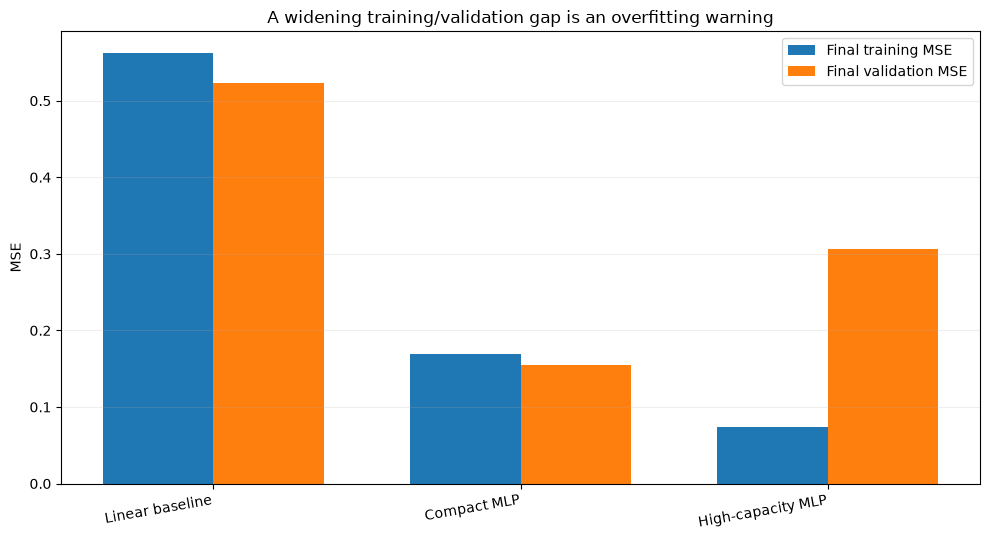

In [46]:
plot_df = comparison_df.set_index("model")
positions = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(positions - width / 2, plot_df["final_train_mse"], width, label="Final training MSE")
ax.bar(positions + width / 2, plot_df["final_validation_mse"], width, label="Final validation MSE")
ax.set_xticks(positions)
ax.set_xticklabels(plot_df.index, rotation=10, ha="right")
ax.set_ylabel("MSE")
ax.set_title("A widening training/validation gap is an overfitting warning")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "generalization_gap_comparison.png", dpi=160)
plt.show()

## 22. Choose a practical model using validation data

The compact network and the high-capacity network reach very similar **best validation losses** in this experiment. The compact model uses far fewer parameters, so it is a sensible choice for this small teaching problem.

This is a practical principle: when validation performance is comparable, a simpler model can be easier to understand, faster to run, and less prone to fitting unnecessary detail.

We now select the compact model and restore its best validation checkpoint. The test set has not been used for these development decisions.

In [47]:
selected_model = CompactMLP()
selected_model.load_state_dict(balanced_result["best_state"])
selected_model.eval()

print("Selected model: CompactMLP")
print("Selected checkpoint epoch:", balanced_result["best_epoch"])
print("Parameter count:", count_parameters(selected_model))
print(f"Validation MSE: {evaluate_mse(selected_model, X_validation, y_validation):.4f}")

Selected model: CompactMLP
Selected checkpoint epoch: 673
Parameter count: 97
Validation MSE: 0.1506


## 23. Evaluate the selected model on the test set

This is the final evaluation. We use the test set only after selecting the model and checkpoint using the training and validation process.

The result is an estimate of how the selected model performs on new examples from the same data-generating process. It is not a guarantee for every future dataset or real-world setting.

In [48]:
# Final test evaluation: do not use this result to go back and tune the model.
selected_model.eval()
with torch.no_grad():
    test_predictions = selected_model(X_test)
    test_mse = float(loss_function(test_predictions, y_test).item())
    test_mae = float(torch.mean(torch.abs(test_predictions - y_test)).item())

print(f"Final test MSE: {test_mse:.4f}")
print(f"Final test MAE: {test_mae:.4f}")

Final test MSE: 0.2488
Final test MAE: 0.4282


## 24. Inspect predictions on held-out test examples

In [49]:
test_results_df = pd.DataFrame({
    "x": X_test.squeeze(1).numpy(),
    "actual_target": y_test.squeeze(1).numpy(),
    "predicted_target": test_predictions.squeeze(1).numpy(),
})
test_results_df["absolute_error"] = (
    test_results_df["actual_target"] - test_results_df["predicted_target"]
).abs()
test_results_df.sort_values("x").head(12)

,x,actual_target,predicted_target,absolute_error
28,-2.899582,0.705419,0.139041,0.566378
14,-2.824268,0.506673,0.095743,0.410931
20,-2.623431,-0.143233,-0.033802,0.109431
8,-2.322176,-0.529287,-0.277248,0.252039
11,-2.221757,-0.211951,-0.373805,0.161853
13,-2.146443,-1.685735,-0.451176,1.234560
30,-1.794979,-1.168985,-0.839038,0.329947
6,-1.217573,-0.476334,-1.199269,0.722935
29,-0.841004,-0.307275,-1.072740,0.765465
15,-0.715481,-0.459685,-0.969224,0.509539


## 25. Generalization is the real goal

A model generalizes when it has learned a useful relationship that continues to work on examples it did not train on.

For this experiment:

- the linear model is too simple for the curved signal;
- the compact neural network learns the main pattern;
- the large network can fit training noise when we continue training too long;
- validation helps us notice when performance on unseen examples stops improving;
- the final test result is reported only after model selection.

The model does not need to reproduce every noisy training point. It needs to capture the useful signal.

## 26. Common misconceptions

1. **“A smaller training loss always means a better model.”** Not necessarily. Validation performance can get worse while training loss keeps falling.
2. **“A large model is always better.”** Capacity helps only when the data and training process support it.
3. **“Overfitting means the model is broken.”** It means the model has fit the training data in a way that does not transfer well to unseen data.
4. **“The test set can be checked after every change.”** Repeatedly using test feedback turns the test set into part of development. Keep it for the final evaluation.
5. **“Generalization means the model works on every possible dataset.”** It refers to performance on new examples from the relevant problem distribution; distribution shifts can still cause failures.

## 27. Knowledge check

Answer these in your own words before checking the notebook outputs:

1. What does it suggest when both training and validation losses remain high?
2. What pattern suggests overfitting?
3. Why can a high-capacity model fit random noise?
4. What is generalization?
5. Why do we choose a checkpoint using validation data rather than the test set?
6. In the high-capacity model, what changed after the best validation epoch?

## 28. Coding challenges

Try these experiments after you understand the baseline:

1. Change the hidden units in `CompactMLP` from 32 to 8 and observe the curve and losses.
2. Train the high-capacity model for fewer epochs, then for more epochs. Compare the training/validation curves.
3. Change `NOISE_STD` from `0.45` to `0.15` and rerun the full notebook. Does the overfitting pattern change?
4. Add more training observations and compare validation behavior.

Change one setting at a time so you can explain which change caused the result.

## 29. Export experiment results

The notebook is the source of truth for all numerical values used by the Manim scenes. The video code reads the files exported below instead of training another model.

In [50]:
# Dataset with split assignments. These records contain observed values only;
# the true signal is included solely as a synthetic visualization reference.
split_by_index = {}
for name, indices in [
    ("train", train_indices),
    ("validation", validation_indices),
    ("test", test_indices),
]:
    for index in indices.tolist():
        split_by_index[index] = name

export_df = pd.DataFrame({
    "example_id": np.arange(N_EXAMPLES),
    "x": X_all.squeeze(1).numpy(),
    "observed_target": y_all.squeeze(1).numpy(),
    "true_signal_for_visualization_only": true_signal_all.squeeze(1).numpy(),
    "split": [split_by_index[i] for i in range(N_EXAMPLES)],
})
export_df.to_csv(OUTPUT_DIR / "dataset_splits.csv", index=False)

all_histories.to_csv(OUTPUT_DIR / "loss_history.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
test_results_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

## 30. Final recap

Remember these three patterns:

- **Underfitting:** the model cannot capture the main pattern; training and validation errors are both high.
- **Overfitting:** the model fits training details too closely; training error is low while validation error is worse.
- **Good generalization:** the model captures useful structure and performs well on unseen examples.

The goal is not to make training loss as small as possible. The goal is to learn a pattern that continues to work beyond the training examples.

**Next lesson:** Lesson 2.1.6 — Build Your First ML Pipeline. We will combine the foundations from this module into a complete, reproducible workflow.